In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

In [5]:
EMOTION_MAP = {
    "01": "neutral",
    "02": "calm",
    "03": "happy",
    "04": "sad",
    "05": "angry",
    "06": "fearful",
    "07": "disgust",
    "08": "surprised",
}

INTENSITY_MAP = {
    "01": "normal",
    "02": "strong",
}

In [6]:
def parse_ravdess_filename(file_path: Path) -> dict:
    """Parses a RAVDESS audio filename into structured metadata fields.

    Filename format: Modality-VocalChannel-Emotion-Intensity-Statement-Repetition-Actor.wav
    Example: 03-01-06-01-02-01-12.wav
    """
    stem = file_path.stem
    parts = stem.split("-")

    if len(parts) != 7:
        raise ValueError(f"Unexpected filename format for: {file_path.name}")

    actor_id = int(parts[6])
    gender = "M" if actor_id % 2 != 0 else "F"

    return {
        "file_name": file_path.name,
        "file_path": str(file_path.resolve()),
        "actor_id": actor_id,
        "gender": gender,
        "emotion": EMOTION_MAP.get(parts[2], "unknown"),
        "intensity": INTENSITY_MAP.get(parts[3], "unknown"),
        "repetition": int(parts[5]),
    }

In [7]:
# Project paths relative to notebooks/
notebook_dir = Path.cwd()
project_root = notebook_dir.parent

raw_data_dir = (
    project_root / "data" / "raw" / "RAVDESS" / "Audio_Speech_Actors_01-24"
)
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# Parse all .wav files across Actor_* folders
wav_files = sorted(raw_data_dir.rglob("*.wav"))
records = [parse_ravdess_filename(path) for path in wav_files]

# Construct DataFrame
df_metadata = pd.DataFrame(records)
df_metadata.sample(5)

,file_name,file_path,actor_id,gender,emotion,intensity,repetition
1190,03-01-07-02-02-01-20.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,20,F,disgust,strong,1
917,03-01-03-02-01-02-16.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,16,F,happy,strong,2
1267,03-01-02-01-02-02-22.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,22,F,calm,normal,2
430,03-01-02-02-02-01-08.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,8,F,calm,strong,1
921,03-01-04-01-01-02-16.wav,/Users/abhisheknigam/workspace/github/my-ai/sp...,16,F,sad,normal,2


In [8]:
# Verify full trial count and class balance
print(df_metadata.info())
print("\nGender Distribution:\n", df_metadata["gender"].value_counts())
print("\nEmotion Distribution:\n", df_metadata["emotion"].value_counts())
print("\nIntensity Distribution:\n", df_metadata["intensity"].value_counts())
print("\nUnique Actors Count:", df_metadata["actor_id"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   file_name   1440 non-null   str  
 1   file_path   1440 non-null   str  
 2   actor_id    1440 non-null   int64
 3   gender      1440 non-null   str  
 4   emotion     1440 non-null   str  
 5   intensity   1440 non-null   str  
 6   repetition  1440 non-null   int64
dtypes: int64(2), str(5)
memory usage: 78.9 KB
None

Gender Distribution:
 gender
M    720
F    720
Name: count, dtype: int64

Emotion Distribution:
 emotion
calm         192
happy        192
sad          192
angry        192
fearful      192
disgust      192
surprised    192
neutral       96
Name: count, dtype: int64

Intensity Distribution:
 intensity
normal    768
strong    672
Name: count, dtype: int64

Unique Actors Count: 24


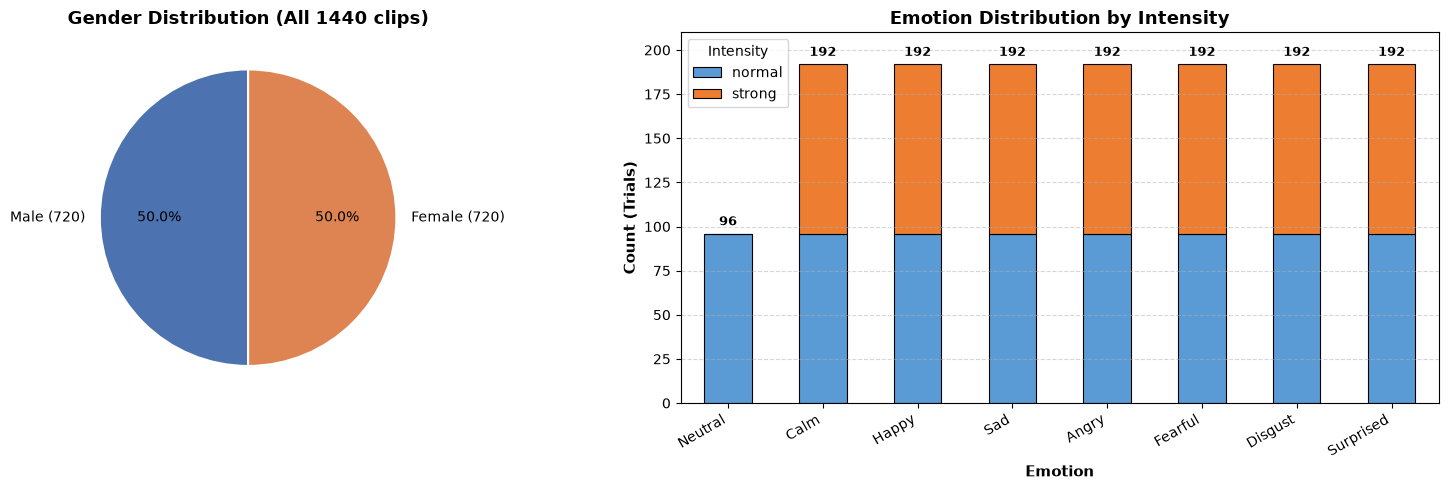

In [9]:
# Visualizing this data

# Set up figure grid
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Gender Pie Plot
gender_counts = df_metadata["gender"].value_counts()
axes[0].pie(
    gender_counts,
    labels=[
        f"Male ({gender_counts.get('M', 0)})",
        f"Female ({gender_counts.get('F', 0)})",
    ],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4C72B0", "#DD8452"],
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)
axes[0].set_title(
    "Gender Distribution (All 1440 clips)", fontsize=13, fontweight="bold"
)

# 2. Stacked Bar Plot for Emotion Distribution by Intensity
emotion_order = [
    "neutral",
    "calm",
    "happy",
    "sad",
    "angry",
    "fearful",
    "disgust",
    "surprised",
]
crosstab_df = (
    pd.crosstab(df_metadata["emotion"], df_metadata["intensity"])
    .reindex(emotion_order)
    .fillna(0)
)

# Guarantee column ordering
crosstab_df = crosstab_df[["normal", "strong"]]

crosstab_df.plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
    color=["#5B9BD5", "#ED7D31"],
    edgecolor="black",
    linewidth=0.8,
)

axes[1].set_title(
    "Emotion Distribution by Intensity", fontsize=13, fontweight="bold"
)
axes[1].set_xlabel("Emotion", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Count (Trials)", fontsize=11, fontweight="bold")
axes[1].set_xticklabels(
    [e.capitalize() for e in emotion_order], rotation=30, ha="right"
)
axes[1].set_ylim(0, 210)
axes[1].legend(title="Intensity", frameon=True)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)

# Annotate total counts atop each bar
for idx, total in enumerate(crosstab_df.sum(axis=1)):
    axes[1].text(
        idx,
        total + 3,
        str(int(total)),
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

plt.tight_layout()

In [10]:
df_metadata.isna().sum()

file_name     0
file_path     0
actor_id      0
gender        0
emotion       0
intensity     0
repetition    0
dtype: int64

In [11]:
# Save to data/processed/
output_path = processed_dir / "ravdess_metadata.csv"
df_metadata.to_csv(output_path, index=False)

print(f"Parsed {len(df_metadata)} files.")
print(f"Saved metadata index to: {output_path}")

Parsed 1440 files.
Saved metadata index to: /Users/abhisheknigam/workspace/github/my-ai/speech-emotion-router/data/processed/ravdess_metadata.csv
